# Unmix the Signal (ICA)

**A complete walkthrough of audio source separation using PCA whitening and a FastICA algorithm implemented from scratch.**

This notebook accompanies the VinnovateIT task. It uses included, reproducible demonstration audio (synthesized speech, procedural instrumental music, and procedural rain ambience). The separation algorithm receives only the mixtures; clean originals are used only after separation to evaluate and align the results.

**Run from the repository root** after installing `requirements.txt` and `pip install -e .`. The notebook reruns the experiments and refreshes their plots and metrics.

## 1. Task requirements covered

- Choose clean sources and mix three sources into three recordings.
- Center the observed mixture channels.
- Implement PCA whitening using covariance and eigendecomposition.
- Implement ICA without a ready-made ICA package.
- Export separated signals as playable WAV audio.
- Evaluate using correlation and scale-invariant SDR, while accounting for permutation/sign/scale ambiguity.
- Compare PCA-only output with ICA output and test additive-noise robustness.

## 2. Mathematical idea

Let the clean sources be `S` and the observed mixed channels be `X`:

\[
X = A S
\]

Here `A` is the mixing matrix. The algorithm is not given `A` or `S` when it separates the signals. It estimates a matrix that transforms `X` into components that are as independent as possible.

**Centering:** subtract each channel's mean.  
**Whitening:** for covariance `C = E D Eᵀ`, apply `Z = D⁻¹ᐟ² Eᵀ X_centered`. This makes covariance approximately the identity.  
**ICA:** update component directions using a non-Gaussianity-related `tanh` contrast and symmetrically decorrelate the directions.

PCA makes dimensions uncorrelated; ICA aims for statistical independence, which is a stronger property.

In [1]:
from pathlib import Path
import sys
import json

# Find the project root whether Jupyter was launched at the root or in notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src" / "unmix_ica").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "unmix_ica").exists():
    raise FileNotFoundError("Open this notebook from the unmix_signal_ica repository or its notebooks/ folder.")
sys.path.insert(0, str(ROOT / "src"))

from unmix_ica.experiment import run_experiment
from unmix_ica.ica import FastICA, center_signals, pca_whiten
from unmix_ica.audio import read_wav

print(f"Project root: {ROOT}")
print("Imports successful. Ready to run the experiment.")

Project root: /mnt/data/unmix_signal_ica
Imports successful. Ready to run the experiment.


## 3. Run the complete experiment

This step creates linear mixtures, runs the whitening + ICA pipeline, exports both raw components and source-matched output WAVs, calculates metrics, and saves figures. Output `separated_*.wav` files are source-matched for convenient comparison; `component_*_raw.wav` files preserve ICA's original order; WAV-safe peak scaling is applied only if needed. The exact numeric output before audio export scaling is saved in `components_raw.npy`.

In [2]:
summary = run_experiment(ROOT, max_iter=500, random_state=42)
print(f"ICA converged: {summary['ica_converged']}")
print(f"Iterations: {summary['ica_iterations']}")
print(f"Mean absolute correlation (PCA only): {summary['baseline_pca_whitening_only']['mean_abs_correlation']:.4f}")
print(f"Mean absolute correlation (PCA + ICA): {summary['ica']['mean_abs_correlation']:.4f}")
print(f"Mean SI-SDR (PCA only): {summary['baseline_pca_whitening_only']['mean_si_sdr_db']:.2f} dB")
print(f"Mean SI-SDR (PCA + ICA): {summary['ica']['mean_si_sdr_db']:.2f} dB")

ICA converged: True
Iterations: 5
Mean absolute correlation (PCA only): 0.7042
Mean absolute correlation (PCA + ICA): 0.9999
Mean SI-SDR (PCA only): 0.09 dB
Mean SI-SDR (PCA + ICA): 39.84 dB


## 4. Inspect source-level metrics

The Hungarian assignment matches components to clean references using absolute correlation. The reported correlation is positive after correcting sign for display. SI-SDR is scale invariant, so the metric remains meaningful despite ICA's scale ambiguity.

In [3]:
import csv

metrics_path = ROOT / "reports" / "metrics" / "source_metrics.csv"
with metrics_path.open(newline="", encoding="utf-8") as f:
    source_metrics = list(csv.DictReader(f))
for row in source_metrics:
    print(f"{row['source_name']}: correlation={float(row['correlation']):.4f}, SI-SDR={float(row['si_sdr_db']):.2f} dB; matched ICA component #{row['estimated_component']}")

print("\nNoise robustness:")
with (ROOT / "reports" / "metrics" / "snr_robustness.csv").open(newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        print(f"Input SNR {float(row['snr_db']):>4.0f} dB: mean |corr|={float(row['mean_abs_correlation']):.4f}, mean SI-SDR={float(row['mean_si_sdr_db']):.2f} dB")

Speech (eSpeak TTS): correlation=1.0000, SI-SDR=41.47 dB; matched ICA component #1
Synthetic instrumental music: correlation=0.9999, SI-SDR=38.43 dB; matched ICA component #3
Synthetic rain ambience: correlation=0.9999, SI-SDR=39.62 dB; matched ICA component #2

Noise robustness:
Input SNR   30 dB: mean |corr|=0.9990, mean SI-SDR=27.08 dB
Input SNR   20 dB: mean |corr|=0.9907, mean SI-SDR=17.24 dB
Input SNR   10 dB: mean |corr|=0.9197, mean SI-SDR=7.41 dB
Input SNR    5 dB: mean |corr|=0.7991, mean SI-SDR=2.48 dB


## 5. Review plots

The plots are also committed as PNG files in `reports/figures/`. The waveform comparison includes original sources, the observed mixture channels, and source-matched ICA estimates. The correlation matrix gives a visual indication of how mixtures and recovered components relate to the clean references.

01_waveform_comparison.png


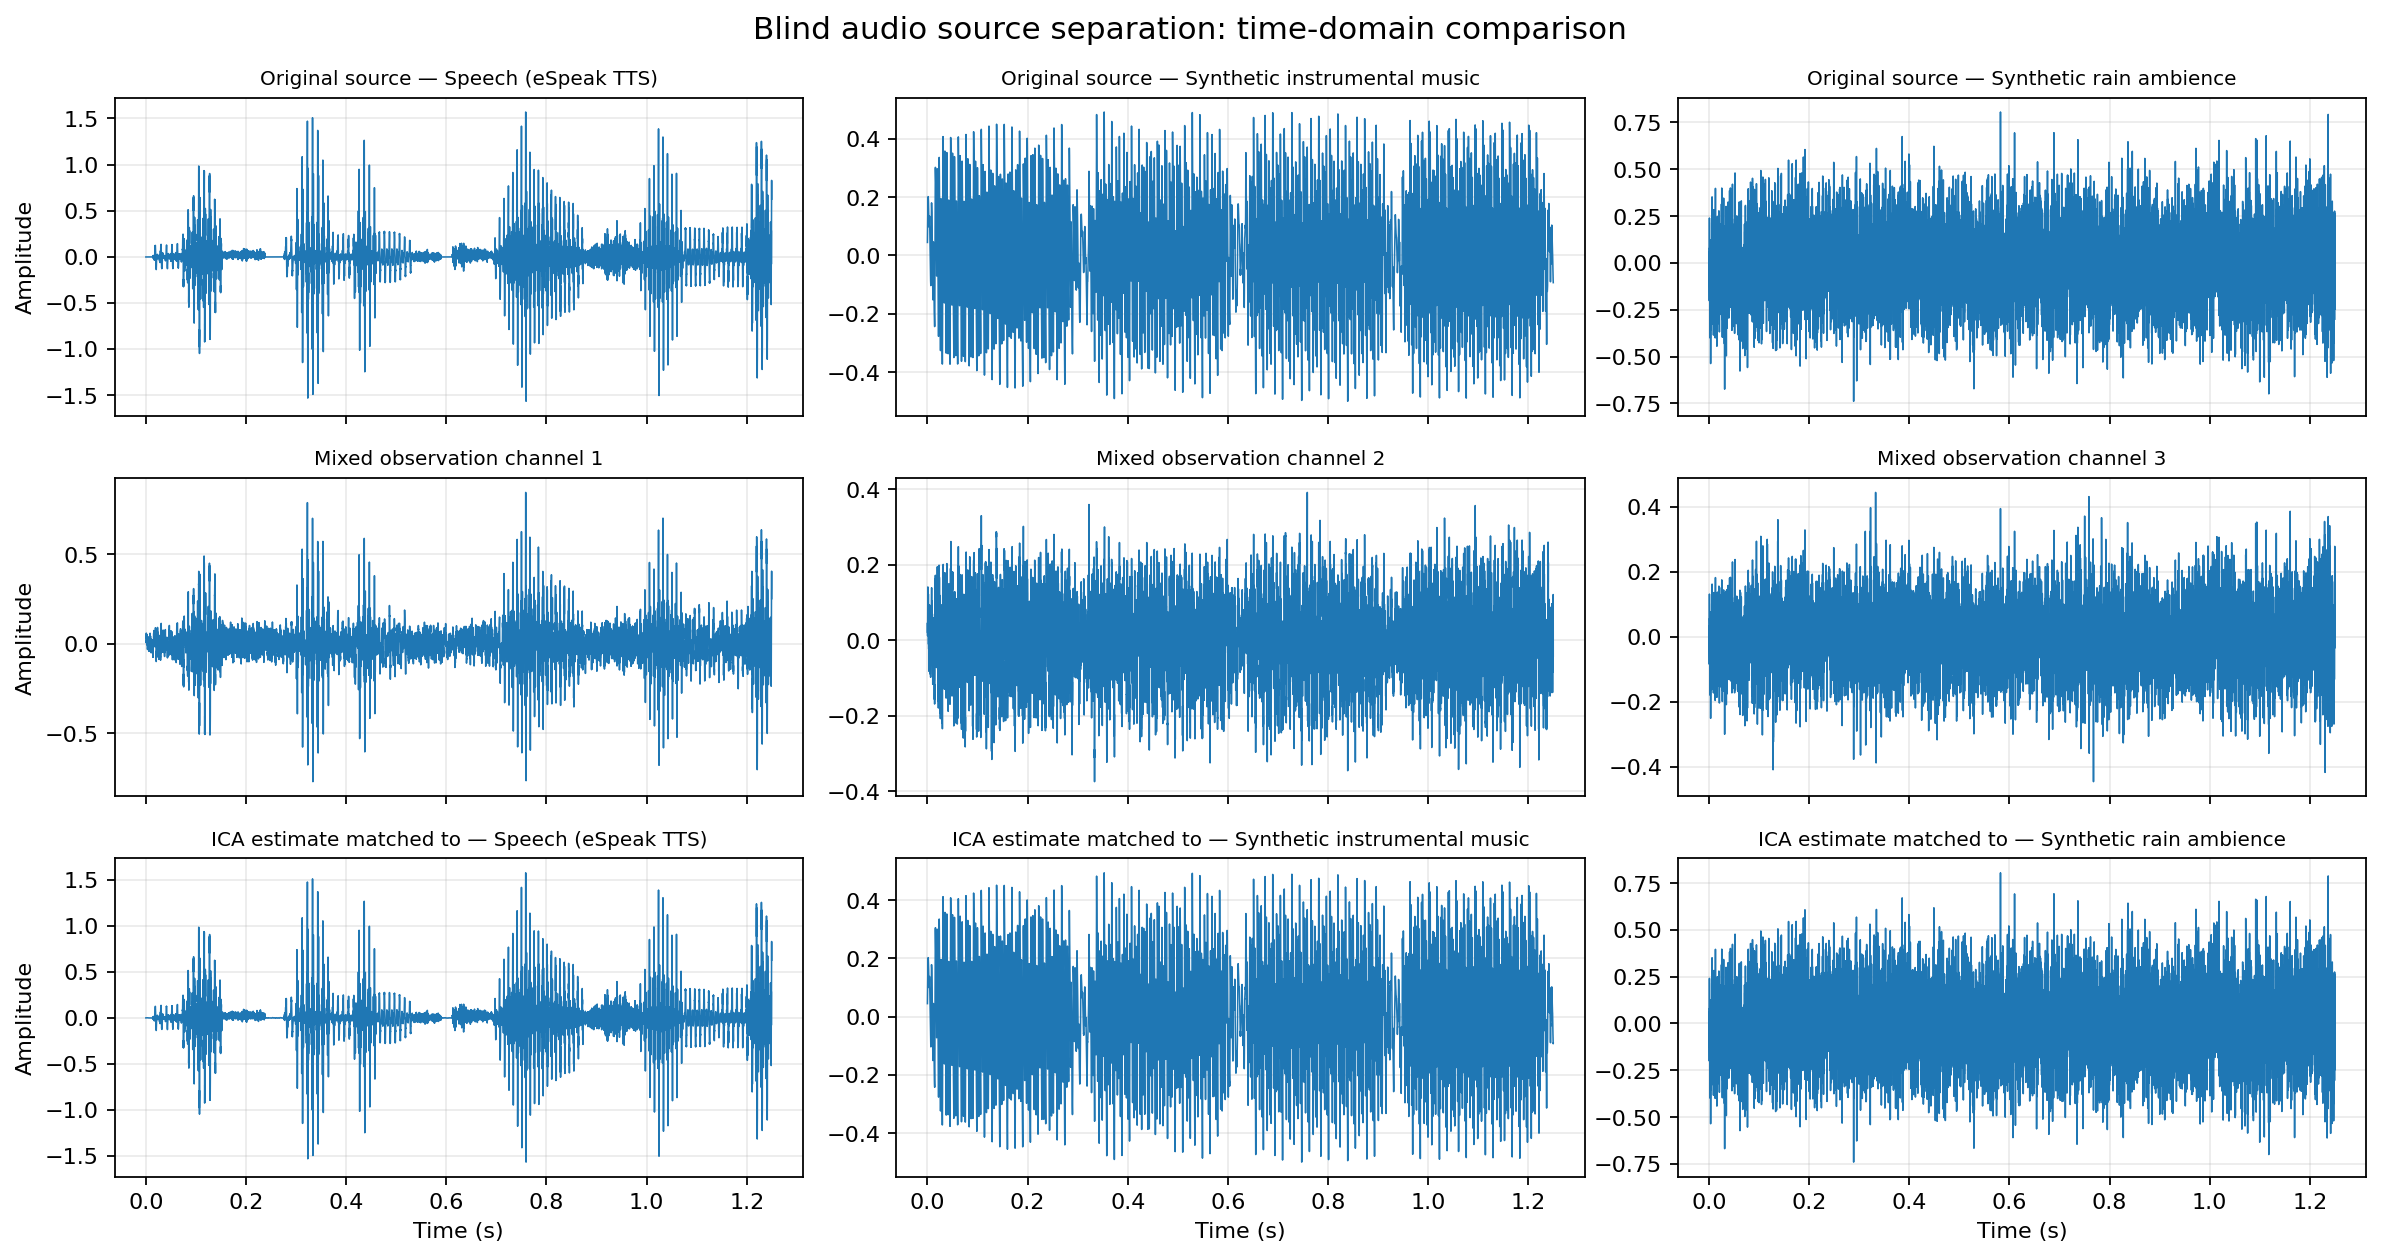

02_correlation_matrices.png


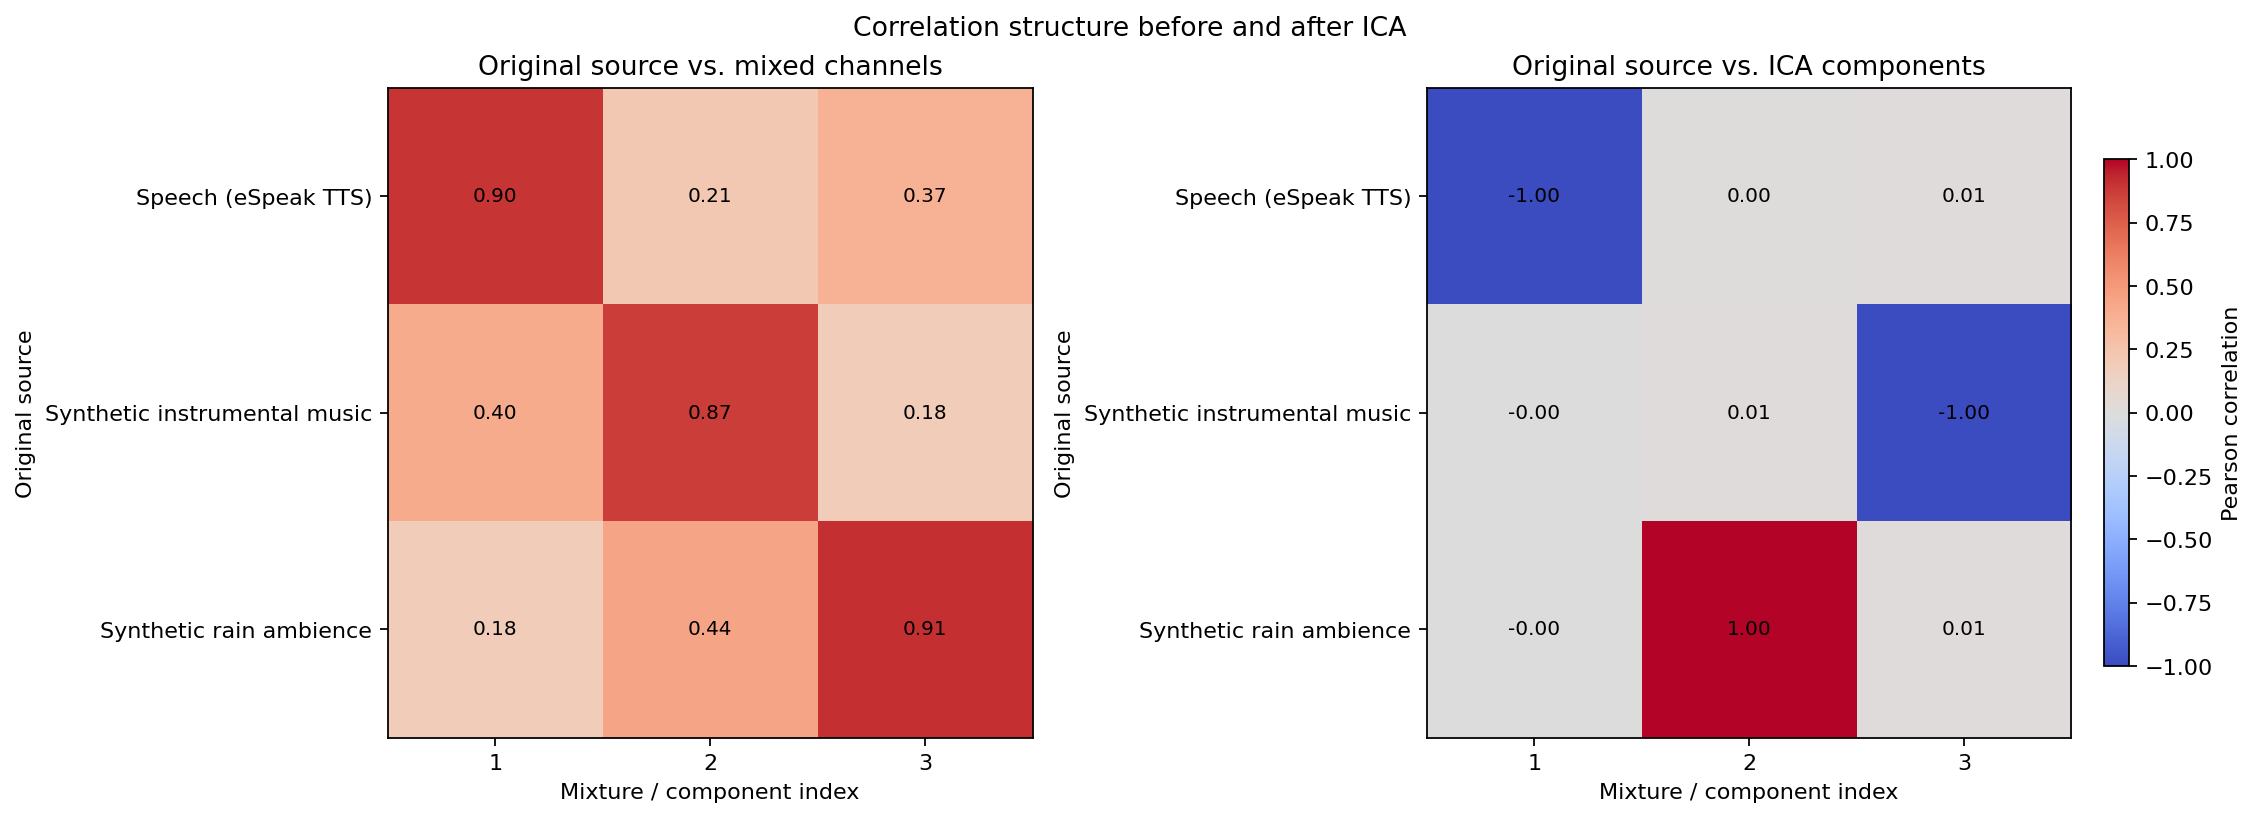

03_metrics_comparison.png


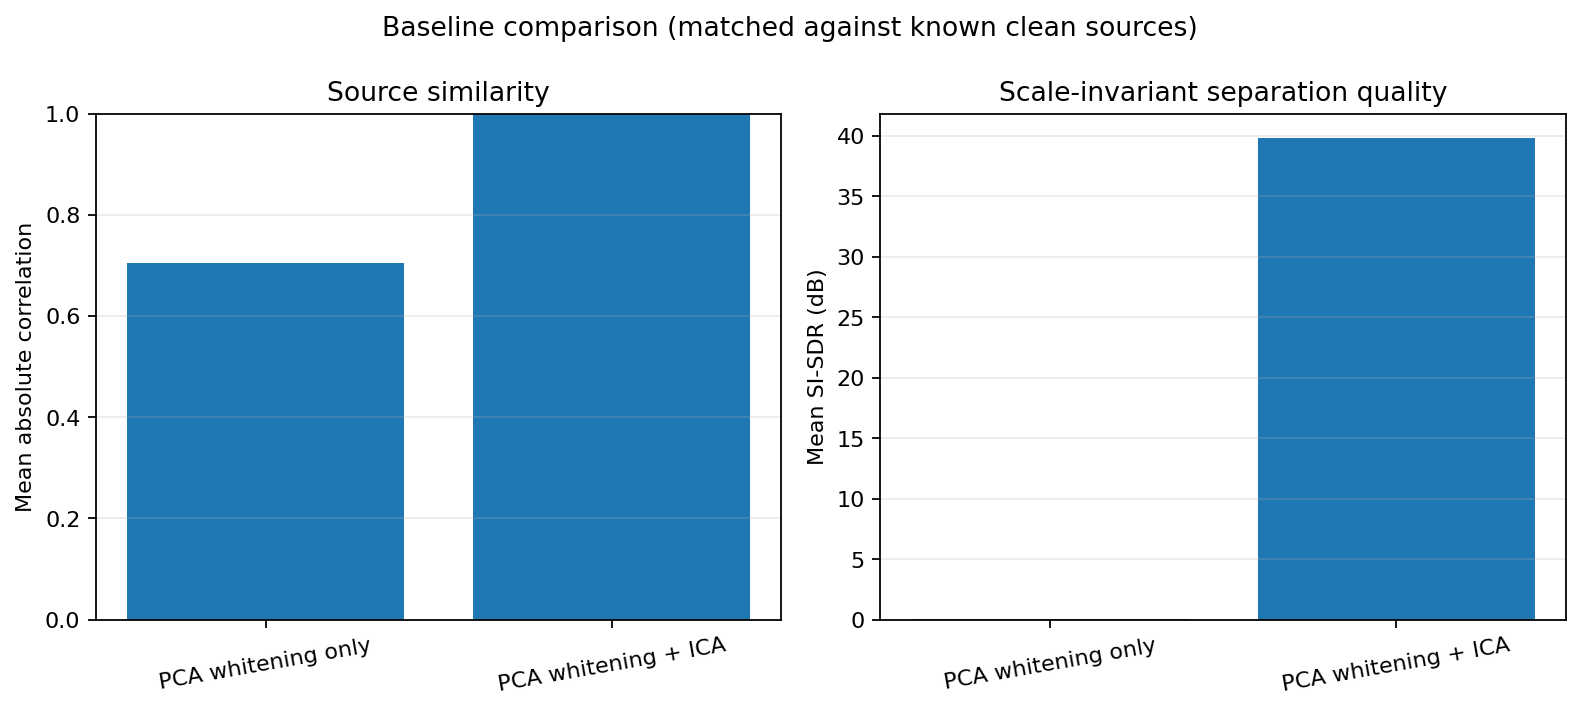

04_ica_convergence.png


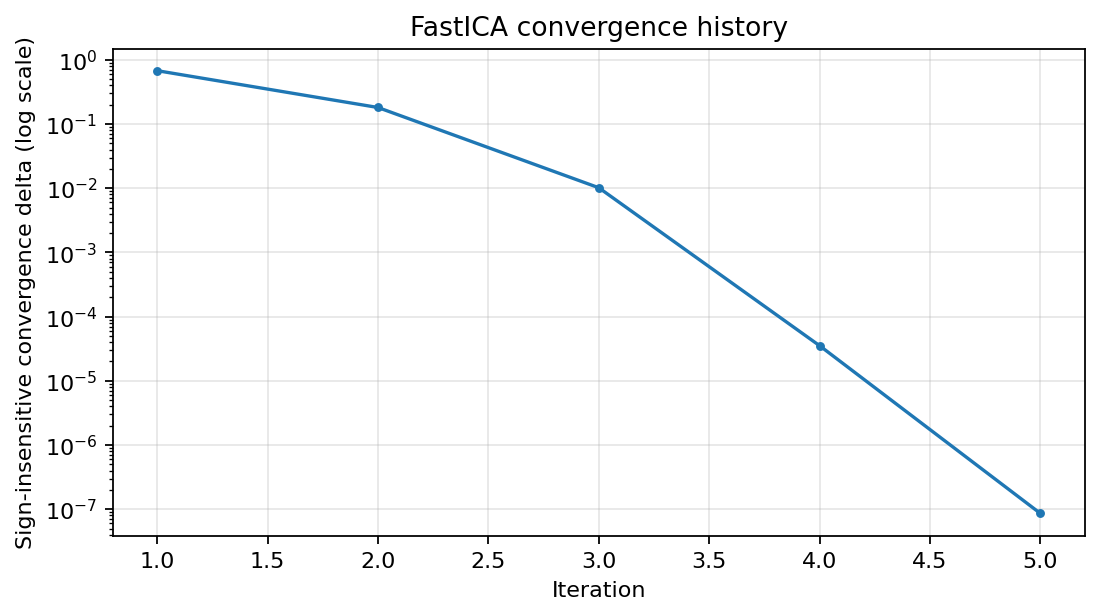

05_snr_robustness.png


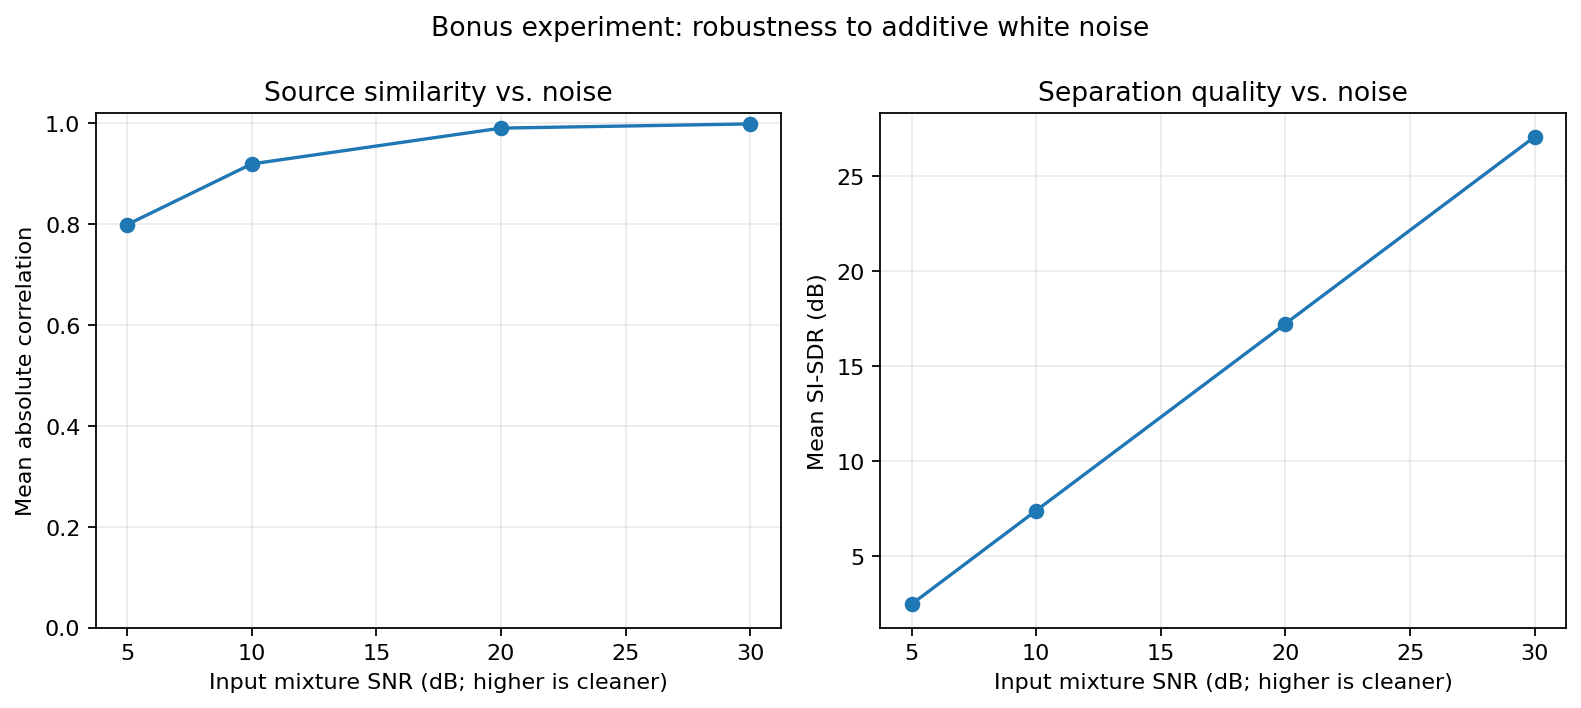

In [4]:
from IPython.display import display, Image

for filename in [
    "01_waveform_comparison.png",
    "02_correlation_matrices.png",
    "03_metrics_comparison.png",
    "04_ica_convergence.png",
    "05_snr_robustness.png",
]:
    print(filename)
    display(Image(filename=str(ROOT / "reports" / "figures" / filename), width=900))

## 6. Verify whitening numerically

The covariance of whitened data should be close to the identity matrix. That means the channels are uncorrelated and have unit variance (up to numerical precision). It does **not** prove statistical independence by itself.

In [5]:
import numpy as np

mixtures = []
for i in range(1, 4):
    sr, signal = read_wav(ROOT / "data" / "mixed" / f"mixture_{i}.wav")
    mixtures.append(signal)
X = np.vstack(mixtures)
Z, whitening_matrix, dewhitening_matrix, eigenvalues = pca_whiten(X)
print("Sample rate:", sr)
print("Covariance of whitened mixtures:")
print(np.round(Z @ Z.T / Z.shape[1], 6))
print("Whitening eigenvalues:", np.round(eigenvalues, 6))

Sample rate: 8000
Covariance of whitened mixtures:
[[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]
Whitening eigenvalues: [0.025931 0.004962 0.004123]


## 7. How to explain the project to a judge

**Why ICA instead of PCA?** PCA only removes correlation. ICA uses higher-order statistical information to estimate independent components.

**What is whitening?** A transform built from the covariance eigenvectors/eigenvalues that makes the covariance approximately the identity matrix, simplifying the remaining ICA search.

**Why can outputs be reordered or sign-flipped?** Component order, sign, and absolute scale are not identifiable from the mixture alone; these are normal ICA ambiguities.

**How do you know separation worked?** This controlled demo compares estimates with known originals after matching components and reports Pearson correlation and SI-SDR. The algorithm itself does not use those originals for fitting.

**What are the limitations?** Basic ICA assumes instantaneous linear mixtures, a full-rank mixing matrix, and reasonably independent sources. Reverberation, dependent sources, Gaussian sources, clipping, and strong noise can reduce quality.

## 8. Limitations and next steps

The provided sources are deliberately reproducible synthetic examples; they are not a substitute for a benchmark of real recordings. A sensible next step is to test appropriately licensed real speech/music/ambience recorded in different environments and evaluate the failure modes of instantaneous ICA. Do not claim that the demo's high scores generalize to arbitrary audio.

## 8. Real-world multi-device extension

The repository also includes `scripts/run_device_recordings.py` for WAV recordings made at the same time by separate phones or microphones. It estimates recording start offsets, resamples all channels to a common rate, aligns the overlap, runs the from-scratch ICA implementation, and writes component WAVs and diagnostic plots.

Follow `docs/REAL_WORLD_RECORDING_GUIDE.md` for the capture protocol. The bundled demo WAVs are procedural/synthesized and are **not** real physical-device recordings. A genuine capture session must be made and inspected before claiming that bonus as completed.

Example command after recording three devices:
```bash
python scripts/run_device_recordings.py --inputs data/real_world/device_1.wav data/real_world/device_2.wav data/real_world/device_3.wav --output-dir outputs/real_world
```

Because the real sources do not have known clean references, this workflow reports convergence and diagnostics instead of inventing SI-SDR scores.